# Who answers the income survey? Reproduction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alestainer/statistics-intuitions/blob/main/notebooks/06-who-answers-the-income-survey.ipynb)

The argument is statistical, so the data is synthetic: a made-up country of 2,000,000 households with a
skewed income distribution. Every household is invited to the survey. The only thing that goes wrong is
**who answers**.

Real published numbers are used in two places only: to give the made-up country a realistic shape, and to
size the homeless population in the last section. The seed is fixed, so every number below is the same on every run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20261110
N_HOUSEHOLDS = 2_000_000

# Census Bureau, "Income in the United States: 2025", Table 2 (all households)
CENSUS_MEDIAN = 87_460
CENSUS_MEAN = 126_700
CENSUS_HOUSEHOLDS = 137_100_000

# HUD, 2025 Annual Homeless Assessment Report, Part 1 (one night in January 2025)
HOMELESS_TOTAL = 745_652
HOMELESS_UNSHELTERED = 266_320

rng = np.random.default_rng(SEED)

## 1. A skewed population: mean and median disagree before any survey

Incomes are drawn from a lognormal distribution. Its two parameters are set so the true median and mean
equal the Census figures. A lognormal has `mean / median = exp(sigma^2 / 2)`, which fixes `sigma`.

In [2]:
sigma = np.sqrt(2 * np.log(CENSUS_MEAN / CENSUS_MEDIAN))
mu = np.log(CENSUS_MEDIAN)
income = rng.lognormal(mu, sigma, N_HOUSEHOLDS)

true_mean = income.mean()
true_median = np.median(income)
below_mean = (income < true_mean).mean()

print(f"sigma               {sigma:.3f}")
print(f"true mean           ${true_mean:,.0f}")
print(f"true median         ${true_median:,.0f}")
print(f"mean / median       {true_mean / true_median:.2f}")
print(f"households below the mean: {below_mean:.1%}")

sigma               0.861
true mean           $126,598
true median         $87,435
mean / median       1.45
households below the mean: 66.6%


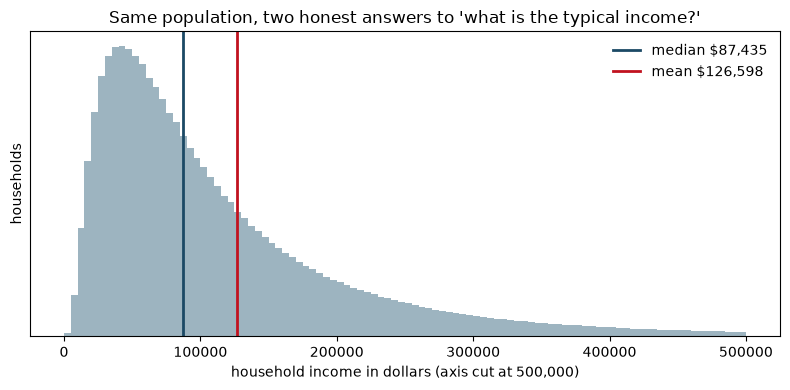

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(income, bins=np.linspace(0, 500_000, 101), color="#9db4c0")
ax.axvline(true_median, color="#1b4965", lw=2, label=f"median ${true_median:,.0f}")
ax.axvline(true_mean, color="#c1121f", lw=2, label=f"mean ${true_mean:,.0f}")
ax.set_xlabel("household income in dollars (axis cut at 500,000)")
ax.set_ylabel("households")
ax.set_yticks([])
ax.legend(frameon=False)
ax.set_title("Same population, two honest answers to 'what is the typical income?'")
fig.tight_layout()
plt.show()

## 2. Create the response bias

Each household gets an income rank from 0 (poorest) to 1 (richest). Its chance of answering depends on
that rank. In every scenario the overall response rate is 70%, so the scenarios differ only in *who* is missing.

| Scenario | Response probability |
|---|---|
| Fair | 70% for everyone |
| Poor answer less | 60% at the bottom, rising to 80% at the top |
| Rich answer less | 80% at the bottom, falling to 60% at the top |
| Both tails answer less | 60% at both ends, 80% in the middle |

In [4]:
rank = income.argsort().argsort() / (N_HOUSEHOLDS - 1)

scenarios = {
    "Fair": np.full(N_HOUSEHOLDS, 0.70),
    "Poor answer less": 0.60 + 0.20 * rank,
    "Rich answer less": 0.80 - 0.20 * rank,
    "Both tails answer less": 0.80 - 0.20 * np.abs(2 * rank - 1),
}

def run_survey(response_probability, rng):
    answered = rng.random(N_HOUSEHOLDS) < response_probability
    return income[answered]

def pct_error(estimate, truth):
    return 100 * (estimate / truth - 1)

results, samples = {}, {}
print(f"{'scenario':<24}{'answered':>9}{'mean':>11}{'error':>8}{'median':>11}{'error':>8}")
for name, probability in scenarios.items():
    sample = run_survey(probability, rng)
    samples[name] = sample
    results[name] = (
        len(sample) / N_HOUSEHOLDS,
        pct_error(sample.mean(), true_mean),
        pct_error(np.median(sample), true_median),
    )
    print(f"{name:<24}{results[name][0]:>9.1%}{sample.mean():>11,.0f}{results[name][1]:>+7.1f}%"
          f"{np.median(sample):>11,.0f}{results[name][2]:>+7.1f}%")

scenario                 answered       mean   error     median   error
Fair                        70.0%    126,550   -0.0%     87,435   +0.0%
Poor answer less            70.0%    134,930   +6.6%     94,470   +8.0%
Rich answer less            70.0%    118,356   -6.5%     81,023   -7.3%
Both tails answer less      69.9%    122,752   -3.0%     87,404   -0.0%


The same result as a picture. In each panel the grey shape is what a fair 70% survey would collect.
The black line is who actually answered. Orange marks households that are missing, green marks households that are
over-represented. The strip under each panel zooms in on the two summary numbers: the hollow marker is the truth,
the filled marker is what the survey reports. The same positions are drawn on the panel above as dotted (truth) and solid (survey) lines.

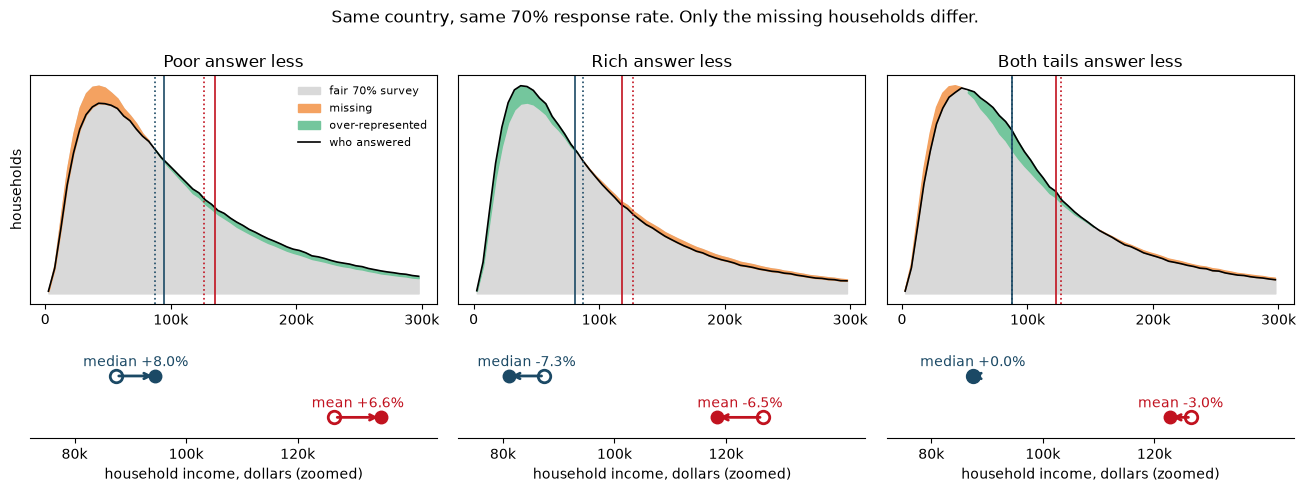

In [5]:
BLUE, RED = "#1b4965", "#c1121f"
edges = np.linspace(0, 300_000, 61)
centers = (edges[:-1] + edges[1:]) / 2
biased = ["Poor answer less", "Rich answer less", "Both tails answer less"]

def draw_shift(names, population, title, columns, zero_label=None):
    """One panel per scenario: who answered against a fair 70% sample of `population`."""
    truth_median, truth_mean = np.median(population), population.mean()
    fair_share = 0.70 * np.histogram(population, edges)[0]
    rows = -(-len(names) // columns)
    fig, axes = plt.subplots(2 * rows, columns, figsize=(4.4 * columns, 4.9 * rows), squeeze=False,
                             gridspec_kw={"height_ratios": [3, 1.25] * rows})
    for index, name in enumerate(names):
        row, column = divmod(index, columns)
        top, strip = axes[2 * row, column], axes[2 * row + 1, column]
        sample = samples[name]
        answered_counts = np.histogram(sample, edges)[0]

        top.fill_between(centers, fair_share, color="#d9d9d9", label="fair 70% survey")
        top.fill_between(centers, fair_share, answered_counts, where=answered_counts < fair_share,
                         color="#f4a261", label="missing")
        top.fill_between(centers, fair_share, answered_counts, where=answered_counts >= fair_share,
                         color="#74c69d", label="over-represented")
        top.plot(centers, answered_counts, color="black", lw=1.2, label="who answered")
        top.set_title(name)
        top.set_yticks([])
        top.set_xticks([0, 100_000, 200_000, 300_000], ["0", "100k", "200k", "300k"])
        if index == 0:
            top.set_ylabel("households")
            top.legend(frameon=False, fontsize=8, loc="upper right")
        if zero_label:
            top.set_xlim(-62_000, 312_000)
            top.text(-4_000, fair_share[0], zero_label, fontsize=8.5, ha="right", va="center", color="#b5651d")

        for height, label, truth, estimate, color in [
            (1, "median", truth_median, np.median(sample), BLUE),
            (0, "mean", truth_mean, sample.mean(), RED),
        ]:
            shift = round(pct_error(estimate, truth), 1) + 0.0
            strip.annotate("", xy=(estimate, height), xytext=(truth, height),
                           arrowprops=dict(arrowstyle="->", color=color, lw=2))
            strip.plot(truth, height, "o", mfc="white", mec=color, ms=9, mew=2)
            strip.plot(estimate, height, "o", color=color, ms=9)
            strip.text((truth + estimate) / 2, height + 0.33, f"{label} {shift:+.1f}%", va="center", ha="center",
                       color=color, fontsize=10)
            for value, style in [(truth, ":"), (estimate, "-")]:
                top.axvline(value, color=color, ls=style, lw=1.2)
        strip.set_xlim(72_000, 145_000)
        strip.set_ylim(-0.5, 1.8)
        strip.set_yticks([])
        strip.set_xticks([80_000, 100_000, 120_000], ["80k", "100k", "120k"])
        strip.set_xlabel("household income, dollars (zoomed)")
        for side in ("top", "left", "right"):
            strip.spines[side].set_visible(False)
    fig.suptitle(title, y=0.995)
    fig.tight_layout()
    plt.show()

draw_shift(biased, income, "Same country, same 70% response rate. Only the missing households differ.", columns=3)

Reading the table:

- **Fair** nonresponse costs nothing except sample size. A 70% response rate is not a problem by itself.
- **Poor answer less** pushes both numbers up.
- **Rich answer less** pushes both numbers down.
- **Both tails answer less** leaves the median where it was and drags the mean down. The median only
  cares whether the missing households are balanced on both sides of it. The mean cares how many dollars went missing.

## 3. How big a gap does it take?

Keep the "poor answer less" shape and change only the gap between the top and bottom response rates.

In [6]:
gaps = np.arange(0, 41, 5)  # percentage points between richest and poorest
sweep_rng = np.random.default_rng(SEED + 1)
mean_errors, median_errors, sweep_medians = [], [], []
for gap in gaps:
    probability = 0.70 + (gap / 100) * (rank - 0.5)
    sample = run_survey(probability, sweep_rng)
    mean_errors.append(pct_error(sample.mean(), true_mean))
    median_errors.append(pct_error(np.median(sample), true_median))
    sweep_medians.append(np.median(sample))

for gap, mean_error, median_error in zip(gaps, mean_errors, median_errors):
    print(f"gap {gap:>2} points   mean {mean_error:+5.1f}%   median {median_error:+5.1f}%")

gap  0 points   mean  -0.0%   median  -0.0%
gap  5 points   mean  +1.7%   median  +2.0%
gap 10 points   mean  +3.2%   median  +3.9%
gap 15 points   mean  +4.8%   median  +6.0%
gap 20 points   mean  +6.6%   median  +8.0%
gap 25 points   mean  +8.1%   median +10.0%
gap 30 points   mean  +9.8%   median +12.2%
gap 35 points   mean +11.4%   median +14.3%
gap 40 points   mean +13.0%   median +16.4%


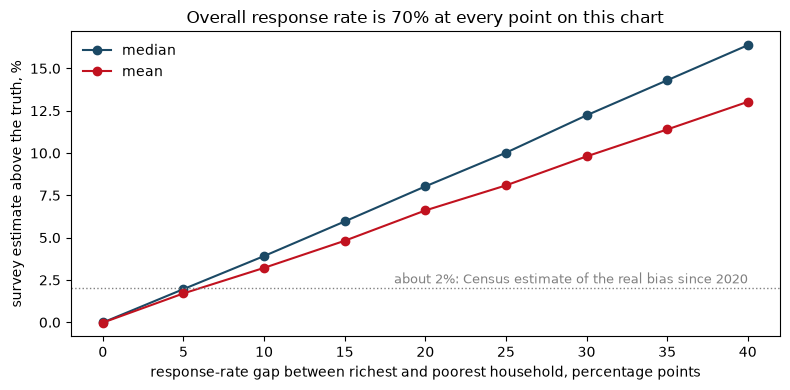

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gaps, median_errors, "o-", color="#1b4965", label="median")
ax.plot(gaps, mean_errors, "o-", color="#c1121f", label="mean")
ax.axhline(2, color="grey", ls=":", lw=1)
ax.text(40, 2.3, "about 2%: Census estimate of the real bias since 2020", ha="right", color="grey", fontsize=9)
ax.set_xlabel("response-rate gap between richest and poorest household, percentage points")
ax.set_ylabel("survey estimate above the truth, %")
ax.set_title("Overall response rate is 70% at every point on this chart")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Does reweighting fix it?

Surveys do not know the income of a household that did not answer. They know things *related* to income,
such as the neighbourhood. Here every household gets a neighbourhood tier (1 to 5) that follows income
imperfectly. Respondents are then reweighted so each tier counts as much as it does in the population.

In [8]:
def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]

weight_rng = np.random.default_rng(SEED + 2)
noisy_signal = np.log(income) + weight_rng.normal(0, sigma, N_HOUSEHOLDS)
tier = np.searchsorted(np.quantile(noisy_signal, [0.2, 0.4, 0.6, 0.8]), noisy_signal)
print(f"correlation between tier and log income: {np.corrcoef(tier, np.log(income))[0, 1]:.2f}")

answered = weight_rng.random(N_HOUSEHOLDS) < scenarios["Poor answer less"]
sample, sample_tier = income[answered], tier[answered]

tier_response_rate = np.array([answered[tier == t].mean() for t in range(5)])
weights = 1 / tier_response_rate[sample_tier]

raw_mean_error = pct_error(sample.mean(), true_mean)
raw_median_error = pct_error(np.median(sample), true_median)
weighted_mean_error = pct_error(np.average(sample, weights=weights), true_mean)
weighted_median_error = pct_error(weighted_median(sample, weights), true_median)

print("response rate by tier:", np.round(tier_response_rate, 3))
print(f"unweighted   mean {raw_mean_error:+.1f}%   median {raw_median_error:+.1f}%")
print(f"reweighted   mean {weighted_mean_error:+.1f}%   median {weighted_median_error:+.1f}%")

correlation between tier and log income: 0.67


response rate by tier: [0.643 0.675 0.699 0.724 0.758]
unweighted   mean +6.7%   median +8.1%
reweighted   mean +3.5%   median +4.5%


Reweighting removes the part of the bias that the tier can see. Inside each tier the poorer households
are still the ones missing, and nothing observable separates them from their neighbours who answered.

## 5. Households that were never invited

Response bias is about people who were asked and stayed silent. People with no address are not asked at all.
The worst case for the statistics: treat every homeless person HUD counted as a separate household with zero income,
and add them to the population.

In [9]:
def add_zero_income_households(count_in_real_country):
    share = count_in_real_country / (CENSUS_HOUSEHOLDS + count_in_real_country)
    synthetic_count = round(share / (1 - share) * N_HOUSEHOLDS)
    return share, np.concatenate([income, np.zeros(synthetic_count)])

homeless_results = {}
for label, count in [("unsheltered only", HOMELESS_UNSHELTERED), ("all homeless", HOMELESS_TOTAL)]:
    share, everyone = add_zero_income_households(count)
    homeless_results[label] = (
        100 * share,
        pct_error(true_mean, everyone.mean()),
        pct_error(true_median, np.median(everyone)),
    )
    print(f"{label:<18} {share:.2%} of households   "
          f"survey mean too high by {homeless_results[label][1]:.2f}%   "
          f"median too high by {homeless_results[label][2]:.2f}%")

unsheltered only   0.19% of households   survey mean too high by 0.19%   median too high by 0.21%


all homeless       0.54% of households   survey mean too high by 0.54%   median too high by 0.59%


The same picture as in section 2, with one change: the truth now includes every homeless person as a zero-income
household. None of them can answer, in any scenario. They are the orange spike at zero. The first panel has no
response bias at all, so its shift is the effect of the missing homeless alone.

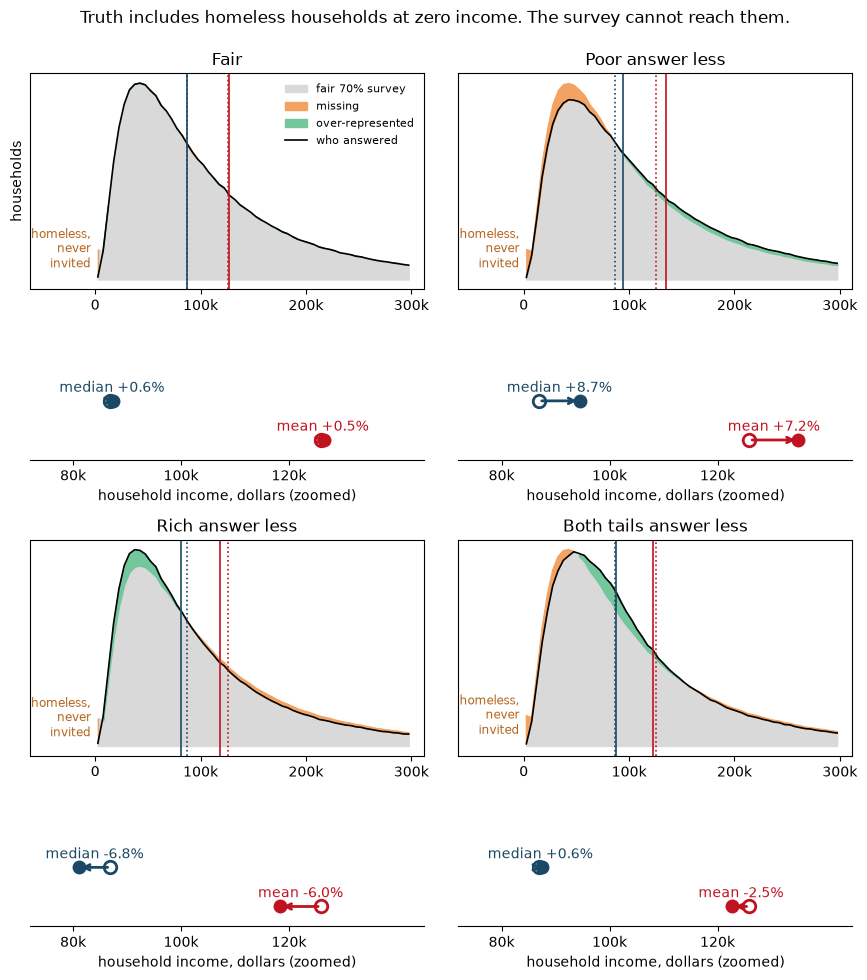

Fair                     mean +0.5%   median +0.6%
Poor answer less         mean +7.2%   median +8.7%
Rich answer less         mean -6.0%   median -6.8%
Both tails answer less   mean -2.5%   median +0.6%


In [10]:
_, everyone = add_zero_income_households(HOMELESS_TOTAL)
draw_shift(["Fair"] + biased, everyone, "Truth includes homeless households at zero income. The survey cannot reach them.", columns=2,
           zero_label="homeless,\nnever\ninvited")

with_homeless = {
    name: (pct_error(samples[name].mean(), everyone.mean()), pct_error(np.median(samples[name]), np.median(everyone)))
    for name in ["Fair"] + biased
}
for name, (mean_error, median_error) in with_homeless.items():
    print(f"{name:<24} mean {mean_error:+.1f}%   median {median_error:+.1f}%")

## 6. How noisy is the homeless count itself?

The 745,652 above is also a survey result. HUD adds up one-night counts from about 385 local areas.
The **sheltered** number comes from shelter bed records. The **unsheltered** number comes from staff and
volunteers who walk the streets. Both describe the same area in the same year, so the first is a yardstick for the second.

The file `hud-pit-counts-by-coc.csv` holds HUD's published counts per area and year, extracted from HUD's workbook
by `extract_hud_pit.py` in the same folder.

In [11]:
from pathlib import Path
import pandas as pd

PIT_FILE = "data/06-who-answers-the-income-survey/hud-pit-counts-by-coc.csv"
RAW = "https://raw.githubusercontent.com/Alestainer/statistics-intuitions/main/"
local = [path for path in (Path("..") / PIT_FILE, Path(PIT_FILE)) if path.exists()]
pit = pd.read_csv(local[0] if local else RAW + PIT_FILE)

latest = pit[pit.year == 2025]
assert latest.overall.sum() == HOMELESS_TOTAL and latest.unsheltered.sum() == HOMELESS_UNSHELTERED
print(f"{pit.coc.nunique()} areas, {pit.year.min()} to {pit.year.max()}; 2025 totals match HUD's report")

413 areas, 2007 to 2025; 2025 totals match HUD's report


Compare each area's count with its own count one year earlier. Rules, fixed before looking at the result:

- both years must be a full count of sheltered and unsheltered people (HUD labels the years where an area skipped the street count);
- the area must have at least 100 sheltered and 100 unsheltered people in the earlier year, so small numbers do not dominate;
- comparisons that touch 2021 are dropped, because the pandemic stopped most street counts.

In [12]:
FULL_COUNT = ("Sheltered and Unsheltered Count", "Sheltered and full unsheltered count")
MIN_PEOPLE = 100

this_year = pit[pit.count_type.isin(FULL_COUNT)]
last_year = this_year.assign(year=this_year.year + 1)
pairs = this_year.merge(last_year, on=["coc", "year"], suffixes=("", "_before"))
pairs = pairs[
    (pairs.sheltered_before >= MIN_PEOPLE)
    & (pairs.unsheltered_before >= MIN_PEOPLE)
    & (pairs.sheltered > 0)
    & (pairs.unsheltered > 0)
    & ~pairs.year.isin([2021, 2022])
]

change = pd.DataFrame({
    "sheltered": (pairs.sheltered / pairs.sheltered_before - 1).abs(),
    "unsheltered": (pairs.unsheltered / pairs.unsheltered_before - 1).abs(),
})
swing = {kind: (100 * change[kind].median(), 100 * (change[kind] > 0.25).mean()) for kind in change}

print(f"{len(pairs)} year-to-year comparisons in {pairs.coc.nunique()} areas, {pairs.year.min() - 1} to {pairs.year.max()}")
for kind, (typical, big) in swing.items():
    print(f"{kind:<12} typical yearly change {typical:4.1f}%   changed by more than 25%: {big:4.1f}% of the time")

2129 year-to-year comparisons in 280 areas, 2009 to 2025
sheltered    typical yearly change  9.4%   changed by more than 25%: 15.3% of the time
unsheltered  typical yearly change 21.0%   changed by more than 25%: 42.6% of the time


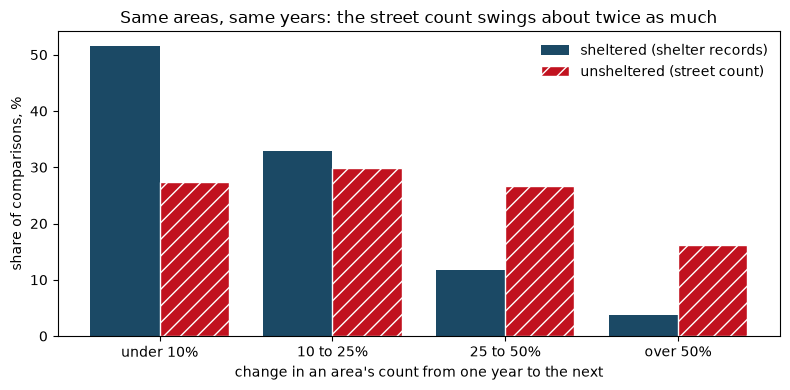

In [13]:
bins = [0, 0.10, 0.25, 0.50, np.inf]
labels = ["under 10%", "10 to 25%", "25 to 50%", "over 50%"]
shares = {kind: 100 * np.histogram(change[kind], bins)[0] / len(change) for kind in change}

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(labels))
ax.bar(x - 0.2, shares["sheltered"], 0.4, color="#1b4965", label="sheltered (shelter records)")
ax.bar(x + 0.2, shares["unsheltered"], 0.4, color="#c1121f", hatch="//", edgecolor="white", label="unsheltered (street count)")
ax.set_xticks(x, labels)
ax.set_xlabel("change in an area's count from one year to the next")
ax.set_ylabel("share of comparisons, %")
ax.set_title("Same areas, same years: the street count swings about twice as much")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Some of that swing is real change. One way to separate out the measurement error: a real change tends to stay,
while an error tends to reverse the next year. If a count is `truth + error`, the covariance between one year's
change and the next year's change equals minus the error variance. So the size of the reversal gives the size of the error.
Changes are in log units; a few changes beyond a factor of 4.5 are left out so they do not decide the answer.

In [14]:
def error_from_reversals(column):
    wide = pairs.assign(step=np.log(pairs[column] / pairs[column + "_before"])).pivot(index="coc", columns="year", values="step")
    first, second = [], []
    for year in wide.columns:
        if year + 1 in wide.columns:
            both = wide[[year, year + 1]].dropna()
            first += list(both[year])
            second += list(both[year + 1])
    first, second = np.array(first), np.array(second)
    keep = (np.abs(first) < 1.5) & (np.abs(second) < 1.5)
    covariance = np.cov(first[keep], second[keep])[0, 1]
    return keep.sum(), 100 * np.sqrt(-covariance)

count_error = {}
for kind in ("sheltered", "unsheltered"):
    used, count_error[kind] = error_from_reversals(kind)
    print(f"{kind:<12} random error in one area's count: about {count_error[kind]:.0f}%   ({used} pairs of consecutive changes)")

sheltered    random error in one area's count: about 8%   (1542 pairs of consecutive changes)
unsheltered  random error in one area's count: about 14%   (1527 pairs of consecutive changes)


This method only sees error that changes from year to year. If the street count misses the same share of
people every year, the numbers look stable and are still too low. Random error mostly cancels in the national total.
A consistent undercount does not.

### Does the noise say how many people are missed?

Not exactly, but it gives a floor. A street count can miss people; it cannot find more people than exist.
So if the same area reports very different numbers in neighbouring years, the low years must have missed
people that the high year found. For each area, compare every count with the best count in the three-year window around it.
The sheltered count gets the same treatment as a control, because real change also creates a gap.

In [15]:
def gap_to_best_neighbour(column):
    wide = pairs.pivot(index="coc", columns="year", values=column)
    before = pairs.pivot(index="coc", columns="year", values=column + "_before")
    gaps = []
    for year in wide.columns:
        if year + 1 in wide.columns:
            window = pd.concat([before[year], wide[year], wide[year + 1]], axis=1).dropna()
            gaps += list(1 - window.iloc[:, 1] / window.max(axis=1))
    return 100 * np.mean(gaps)

best_gap = {kind: gap_to_best_neighbour(kind) for kind in ("sheltered", "unsheltered")}
for kind, gap in best_gap.items():
    print(f"{kind:<12} an average count is {gap:.1f}% below the best count in its three-year window")
print(f"extra gap in the street count: {best_gap['unsheltered'] - best_gap['sheltered']:.1f} points")

sheltered    an average count is 9.6% below the best count in its three-year window
unsheltered  an average count is 16.1% below the best count in its three-year window
extra gap in the street count: 6.5 points


The extra gap is a floor under the undercount, and a low one. It assumes the best year found everyone, which
no street count does, and it cannot see people who are missed every year. To get the level you need an independent
check, such as decoys placed among the people to be counted.

## 7. Households that never form

A household is everyone who lives in one housing unit. An adult who lives with their parents is not a separate
household, whatever the reason, and their income is added to the parents' income.

Start from the same 2,000,000 incomes, but read them as "households that would exist if everyone could afford their
own place". Then one in ten of them, all from the lower-income half, moves in with a randomly chosen other household.
Nobody's income changes.

In [16]:
merge_rng = np.random.default_rng(SEED + 3)
MOVER_SHARE = 0.10

lower_half = np.flatnonzero(rank < 0.5)
movers = merge_rng.choice(lower_half, int(MOVER_SHARE * N_HOUSEHOLDS), replace=False)
stays = np.ones(N_HOUSEHOLDS, dtype=bool)
stays[movers] = False
hosts = merge_rng.choice(np.flatnonzero(stays), len(movers), replace=False)

observed = income.copy()
observed[hosts] += income[movers]
observed = observed[stays]

merged_mean_error = pct_error(observed.mean(), true_mean)
merged_median_error = pct_error(np.median(observed), true_median)
print(f"households before: {N_HOUSEHOLDS:,}   after: {len(observed):,}")
print(f"mean household income    ${true_mean:,.0f} -> ${observed.mean():,.0f}  ({merged_mean_error:+.1f}%)")
print(f"median household income  ${true_median:,.0f} -> ${np.median(observed):,.0f}  ({merged_median_error:+.1f}%)")

households before: 2,000,000   after: 1,800,000
mean household income    $126,598 -> $140,665  (+11.1%)
median household income  $87,435 -> $103,608  (+18.5%)


Total income is unchanged and both statistics rise. The survey can be perfect and this still happens, because it is
not an error in the survey. It is a consequence of counting households instead of people.

## 8. What a wrong median does to an income limit

Housing programs use the median as a ruler. A common rule: a household qualifies if its income is under 80% of the
area median, and the rent of a restricted unit is capped at 30% of that limit. If the median is too high, the limit
and the rent cap are too high by the same percentage.

The truth here is every household living separately plus the homeless households at zero. The reported median
stacks the errors from the earlier sections one at a time: homeless people are not counted, one in ten households
is doubled up, and then the poor answer less. Each person is tested with their own income, because a doubled-up
adult who applies for a unit applies alone.

In [17]:
LIMIT_SHARE = 0.80
RENT_SHARE = 0.30
limit_rng_seed = SEED + 4

def biased_survey(values, gap_points):
    value_rank = values.argsort().argsort() / (len(values) - 1)
    probability = 0.70 + (gap_points / 100) * (value_rank - 0.5)
    return values[np.random.default_rng(limit_rng_seed).random(len(values)) < probability]

stages = {
    "truth": everyone,
    "homeless not counted": income,
    "+ one in ten doubled up": observed,
    "+ poor answer less (5-point gap)": biased_survey(observed, 5),
    "+ poor answer less (20-point gap)": biased_survey(observed, 20),
}
true_limit = LIMIT_SHARE * np.median(everyone)
limit_results = {}
print(f"{'reported by':<34}{'median':>10}{'80% limit':>11}{'error':>8}{'under limit':>13}{'only by error':>15}{'rent cap':>10}")
for name, values in stages.items():
    limit = LIMIT_SHARE * np.median(values)
    limit_error = pct_error(limit, true_limit)
    under = 100 * (everyone < limit).mean()
    only_by_error = 100 * ((everyone >= true_limit) & (everyone < limit)).mean()
    monthly_rent_cap = RENT_SHARE * limit / 12
    limit_results[name] = (limit, limit_error, under, only_by_error, monthly_rent_cap)
    print(f"{name:<34}{np.median(values):>10,.0f}{limit:>11,.0f}{limit_error:>+7.1f}%{under:>12.1f}%{only_by_error:>14.1f}%{monthly_rent_cap:>10,.0f}")

reported by                           median  80% limit   error  under limit  only by error  rent cap
truth                                 86,923     69,538   +0.0%        39.8%           0.0%     1,738
homeless not counted                  87,435     69,948   +0.6%        40.1%           0.3%     1,749
+ one in ten doubled up              103,608     82,886  +19.2%        47.8%           8.0%     2,072
+ poor answer less (5-point gap)     105,387     84,310  +21.2%        48.6%           8.8%     2,108
+ poor answer less (20-point gap)    110,976     88,781  +27.7%        51.0%          11.2%     2,220


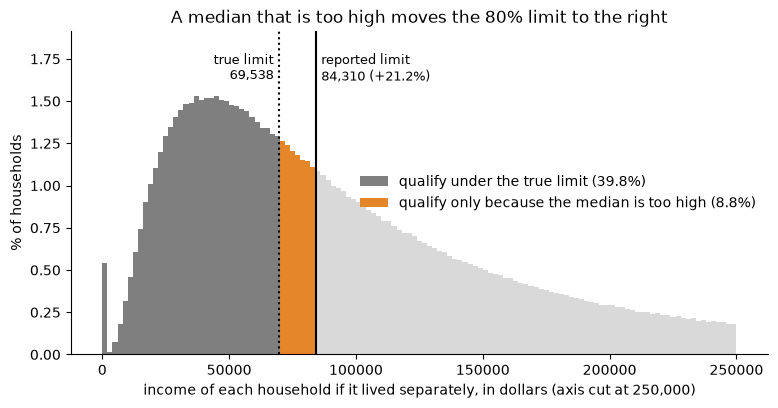

In [18]:
shown = "+ poor answer less (5-point gap)"
reported_limit = limit_results[shown][0]
bins = np.linspace(0, 250_000, 126)
centers = (bins[:-1] + bins[1:]) / 2
counts, _ = np.histogram(everyone, bins)
share_per_bin = 100 * counts / len(everyone)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(centers, share_per_bin, width=bins[1] - bins[0], color="#d9d9d9")
qualifies = centers < true_limit
by_error = (centers >= true_limit) & (centers < reported_limit)
ax.bar(centers[qualifies], share_per_bin[qualifies], width=bins[1] - bins[0], color="#7f7f7f",
       label=f"qualify under the true limit ({limit_results['truth'][2]:.1f}%)")
ax.bar(centers[by_error], share_per_bin[by_error], width=bins[1] - bins[0], color="#e6862a",
       label=f"qualify only because the median is too high ({limit_results[shown][3]:.1f}%)")
ax.axvline(true_limit, color="black", linestyle=":")
ax.axvline(reported_limit, color="black")
top = share_per_bin[1:].max()
ax.set_ylim(0, top * 1.25)
ax.text(true_limit - 2_000, top * 1.17, f"true limit\n{true_limit:,.0f}", ha="right", va="top", fontsize=9)
ax.text(reported_limit + 2_000, top * 1.17, f"reported limit\n{reported_limit:,.0f} ({limit_results[shown][1]:+.1f}%)",
        ha="left", va="top", fontsize=9)
ax.set_xlabel("income of each household if it lived separately, in dollars (axis cut at 250,000)")
ax.set_ylabel("% of households")
ax.set_title("A median that is too high moves the 80% limit to the right")
ax.legend(loc="center right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Nobody who should qualify is shut out, because the limit moved up. The cost is elsewhere: the same number of units
now has a larger pool of applicants, the added applicants are the highest earners in the pool, and the rent cap rose
for every tenant by the same percentage as the median.

## 9. Who can afford the rent that the limit allows

The rent cap is 30% of the income **limit**, not 30% of the tenant's income. Only a household exactly at the limit
pays 30%. A household at X% of the median in a unit capped at Y% pays `30% * Y / X` of its income.

Real anchor: Hawaii's housing agency publishes the 2026 maximum rents for Honolulu. The numbers below are copied
from that table, with the state minimum wage for comparison.

In [19]:
HONOLULU_MEDIAN = 133_400                     # HHFDC, Honolulu County, effective May 1, 2026
HONOLULU_LIMIT_4_PERSON = {80: 123_200, 100: 154_000}
HONOLULU_ONE_BEDROOM_RENT = {30: 866, 50: 1_443, 60: 1_732, 80: 2_310, 100: 2_887}
HAWAII_MINIMUM_WAGE = 16.00                   # per hour from January 1, 2026
full_time_pay = HAWAII_MINIMUM_WAGE * 40 * 52

print(f"full-time minimum wage pay: ${full_time_pay:,.0f} a year")
print(f"the '80%' limit for four people is {100 * HONOLULU_LIMIT_4_PERSON[80] / HONOLULU_MEDIAN:.0f}% of the published median")
print()
print(f"{'unit capped at':<16}{'max rent':>10}{'income needed':>15}{'hourly wage needed':>20}{'share of min-wage pay':>23}")
honolulu = {}
for level, rent in HONOLULU_ONE_BEDROOM_RENT.items():
    needed = rent * 12 / RENT_SHARE
    one_job = 100 * rent * 12 / full_time_pay
    hourly_needed = needed / (40 * 52)
    honolulu[level] = (needed, one_job, hourly_needed)
    print(f"{str(level) + '% of median':<16}{rent:>10,}{needed:>15,.0f}{hourly_needed:>20.2f}{one_job:>22.0f}%")

full-time minimum wage pay: $33,280 a year
the '80%' limit for four people is 92% of the published median

unit capped at    max rent  income needed  hourly wage needed  share of min-wage pay
30% of median          866         34,640               16.65                    31%
50% of median        1,443         57,720               27.75                    52%
60% of median        1,732         69,280               33.31                    62%
80% of median        2,310         92,400               44.42                    83%
100% of median       2,887        115,480               55.52                   104%


The same thing in the made-up country. Take a unit capped at 80% of the median and ask each household that
qualifies what share of its income the maximum rent would take. Then repeat with the reported median from section 8.

In [20]:
def burden_table(limit, label):
    rent = RENT_SHARE * limit / 12
    qualifies = everyone < true_limit
    share_of_income = np.divide(rent * 12, everyone, out=np.full(len(everyone), np.inf), where=everyone > 0)
    burden = share_of_income[qualifies]
    over_30 = 100 * (burden > 0.30).mean()
    over_50 = 100 * (burden > 0.50).mean()
    typical = 100 * np.median(burden)
    print(f"{label:<34} rent {rent:>6,.0f}   pay over 30%: {over_30:>5.1f}%   over 50%: {over_50:>5.1f}%   typical share: {typical:.0f}%")
    return over_30, over_50, typical

print("households that qualify under the true limit, in a unit at the maximum rent")
burden_results = {
    "true": burden_table(true_limit, "limit from the true median"),
    "reported": burden_table(limit_results[shown][0], "limit from the reported median"),
}
lowest_burden_reported = 100 * RENT_SHARE * limit_results[shown][0] / true_limit
print(f"with the reported median, the best-off household that truly qualifies pays {lowest_burden_reported:.1f}%")

households that qualify under the true limit, in a unit at the maximum rent
limit from the true median         rent  1,738   pay over 30%: 100.0%   over 50%:  50.1%   typical share: 50%
limit from the reported median     rent  2,108   pay over 30%: 100.0%   over 50%:  66.9%   typical share: 61%
with the reported median, the best-off household that truly qualifies pays 36.4%


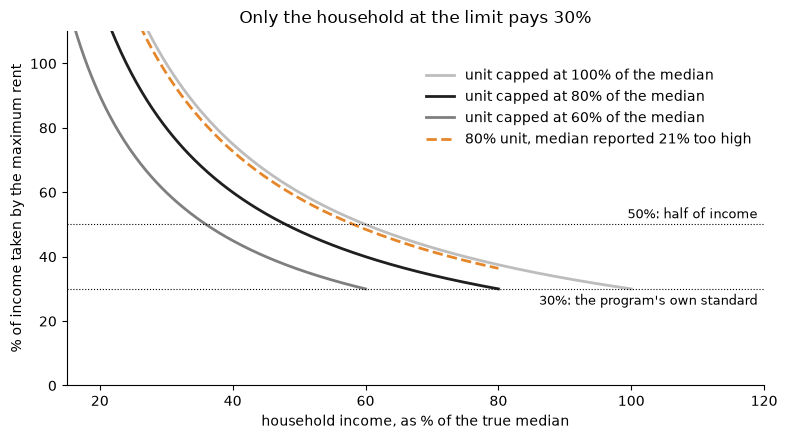

In [21]:
true_median_all = np.median(everyone)
position = np.linspace(15, 120, 400)          # household income as % of the true median
fig, ax = plt.subplots(figsize=(9, 4.6))
for level, color in [(100, "#bdbdbd"), (80, "#1f1f1f"), (60, "#7f7f7f")]:
    visible = position <= level
    ax.plot(position[visible], 100 * RENT_SHARE * level / position[visible], color=color, linewidth=2,
            label=f"unit capped at {level}% of the median")
inflation = limit_results[shown][0] / true_limit
visible = position <= 80
ax.plot(position[visible], 100 * RENT_SHARE * 80 * inflation / position[visible], color="#e6862a", linewidth=2,
        linestyle="--", label=f"80% unit, median reported {limit_results[shown][1]:.0f}% too high")
ax.axhline(30, color="black", linewidth=0.8, linestyle=":")
ax.axhline(50, color="black", linewidth=0.8, linestyle=":")
ax.text(119, 28.5, "30%: the program's own standard", ha="right", va="top", fontsize=9)
ax.text(119, 51, "50%: half of income", ha="right", va="bottom", fontsize=9)
ax.set_ylim(0, 110)
ax.set_xlim(15, 120)
ax.set_xlabel("household income, as % of the true median")
ax.set_ylabel("% of income taken by the maximum rent")
ax.set_title("Only the household at the limit pays 30%")
ax.legend(loc="upper right", frameon=False, bbox_to_anchor=(1.0, 0.93))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Each line ends at 30% on the right, at the household that sits exactly on the limit. Everybody to the left of that
point pays more, and the people the program is named for are far to the left.

### What share of its target does the program serve?

The program is for the households under the true limit. Count a household as served if the maximum rent takes at
most a set share of its income. At the program's own 30% the answer is zero by construction, so the table also
shows looser standards. The last column counts everybody who is admitted and served, including households that
qualify only because the median is too high.

In [22]:
TOLERANCES = (0.30, 0.35, 0.40, 0.50)
target = everyone < true_limit
served_results = {}
print(f"the target group is {100 * target.mean():.1f}% of all households")
for label, limit in [("true", true_limit), ("reported", limit_results[shown][0])]:
    annual_rent = RENT_SHARE * limit
    print(f"\nrent cap from the {label} median: {annual_rent / 12:,.0f} a month")
    print(f"{'rent may take':<16}{'income needed':>15}{'target served':>15}{'= % of all':>12}{'admitted and served, % of all':>32}")
    for tolerance in TOLERANCES:
        income_needed = annual_rent / tolerance
        target_served = target & (everyone >= income_needed)
        admitted_served = (everyone < limit) & (everyone >= income_needed)
        row = (100 * target_served.sum() / target.sum(), 100 * target_served.mean(), 100 * admitted_served.mean())
        served_results[(label, tolerance)] = row
        print(f"{'at most ' + format(tolerance, '.0%'):<16}{income_needed:>15,.0f}{row[0]:>14.1f}%{row[1]:>11.1f}%{row[2]:>31.1f}%")

the target group is 39.8% of all households

rent cap from the true median: 1,738 a month
rent may take     income needed  target served  = % of all   admitted and served, % of all
at most 30%              69,538           0.0%        0.0%                            0.0%
at most 35%              59,604          16.6%        6.6%                            6.6%
at most 40%              52,154          30.1%       12.0%                           12.0%
at most 50%              41,723          49.9%       19.9%                           19.9%

rent cap from the reported median: 2,108 a month
rent may take     income needed  target served  = % of all   admitted and served, % of all
at most 30%              84,310           0.0%        0.0%                            0.0%
at most 35%              72,266           0.0%        0.0%                            7.0%
at most 40%              63,232          10.4%        4.1%                           12.9%
at most 50%              50,586          

With the reported median, about the same share of the country is admitted and served, but most of those households
are above the true limit. A count of households served cannot see the error.

### What the higher cap is worth to the owner of the unit

Three rents for the same unit: the rent that half of the target group could pay within 30% of income, the maximum
rent from the true median, and the maximum rent from the reported median. The differences are the extra rent the
rule allows, per unit. They are upper bounds: an owner can charge less than the maximum.

For Honolulu, the published "80%" one-bedroom rent is compared with the rent that a plain 80% of the published
median would give. The one-bedroom rent uses 1.5 persons, the mean of the 1-person (0.70) and 2-person (0.80)
family-size factors in the agency's table.

In [23]:
target_median_income = np.median(everyone[target])
rents = {
    "half of the target can pay 30%": RENT_SHARE * target_median_income / 12,
    "maximum, true median": RENT_SHARE * true_limit / 12,
    "maximum, reported median": RENT_SHARE * limit_results[shown][0] / 12,
}
base = rents["half of the target can pay 30%"]
print(f"median income of the target group: {target_median_income:,.0f}")
for name, rent in rents.items():
    print(f"{name:<34}{rent:>8,.0f} a month   {12 * (rent - base):>8,.0f} a year above the first row   x100 units: {1200 * (rent - base):>10,.0f}")
mirage_per_unit = 12 * (rents["maximum, reported median"] - rents["maximum, true median"])
design_per_unit = 12 * (rents["maximum, true median"] - base)
print(f"from the rule itself: {design_per_unit:,.0f} a year per unit;  from the wrong median: {mirage_per_unit:,.0f} more")

ONE_BEDROOM_FACTOR = (0.70 + 0.80) / 2
plain_80_rent = RENT_SHARE * 0.80 * HONOLULU_MEDIAN * ONE_BEDROOM_FACTOR / 12
published_check = RENT_SHARE * HONOLULU_LIMIT_4_PERSON[80] * ONE_BEDROOM_FACTOR / 12
assert round(published_check) == HONOLULU_ONE_BEDROOM_RENT[80]
honolulu_extra = 12 * (HONOLULU_ONE_BEDROOM_RENT[80] - plain_80_rent)
print(f"\nHonolulu one-bedroom at '80%': published {HONOLULU_ONE_BEDROOM_RENT[80]:,}, plain 80% of the median {plain_80_rent:,.0f}"
      f" -> {honolulu_extra:,.0f} a year per unit, {100 * honolulu_extra:,.0f} per 100 units")

median income of the target group: 41,661
half of the target can pay 30%       1,042 a month          0 a year above the first row   x100 units:          0
maximum, true median                 1,738 a month      8,363 a year above the first row   x100 units:    836,318
maximum, reported median             2,108 a month     12,795 a year above the first row   x100 units:  1,279,467
from the rule itself: 8,363 a year per unit;  from the wrong median: 4,431 more

Honolulu one-bedroom at '80%': published 2,310, plain 80% of the median 2,001 -> 3,708 a year per unit, 370,800 per 100 units


## 10. Response bias alone: who the program ends up serving

This section uses nothing but response bias. The truth is the 2,000,000 households from section 1, with no homeless
households added and nobody doubled up. The reported medians are the ones from the sweep in section 3.

The target group is every household under 80% of the true median. A household is served if it is admitted (its
income is under the reported limit) and the maximum rent takes at most a set share of its income. Served households
are split in two: those in the target group, and those that qualify only because the reported limit is too high.

In [24]:
plain_true_limit = LIMIT_SHARE * true_median
plain_target = income < plain_true_limit
STANDARDS = (0.35, 0.40)
bias_results = {standard: [] for standard in STANDARDS}
print(f"true limit {plain_true_limit:,.0f}; target group {100 * plain_target.mean():.1f}% of households")
for standard in STANDARDS:
    print(f"\nserved = rent takes at most {standard:.0%} of income")
    print(f"{'gap':>4}{'median error':>14}{'max rent':>10}{'target served':>15}{'of all: target':>16}{'of all: only by error':>23}{'wrong share of served':>23}")
    for gap, reported_median, error in zip(gaps, sweep_medians, median_errors):
        reported_limit = LIMIT_SHARE * reported_median
        income_needed = RENT_SHARE * reported_limit / standard
        can_pay = (income >= income_needed) & (income < reported_limit)
        served_target = can_pay & plain_target
        served_by_error = can_pay & ~plain_target
        row = (
            100 * served_target.sum() / plain_target.sum(),
            100 * served_target.mean(),
            100 * served_by_error.mean(),
            100 * served_by_error.sum() / max(can_pay.sum(), 1),
        )
        bias_results[standard].append(row)
        print(f"{gap:>4}{error:>+13.1f}%{RENT_SHARE * reported_limit / 12:>10,.0f}{row[0]:>14.1f}%{row[1]:>15.1f}%{row[2]:>22.1f}%{row[3]:>22.0f}%")

true limit 69,948; target group 39.8% of households

served = rent takes at most 35% of income
 gap  median error  max rent  target served  of all: target  of all: only by error  wrong share of served
   0         -0.0%     1,748          16.8%            6.7%                   0.0%                     0%
   5         +2.0%     1,783          14.8%            5.9%                   0.9%                    13%
  10         +3.9%     1,817          12.7%            5.1%                   1.7%                    26%
  15         +6.0%     1,853          10.7%            4.2%                   2.6%                    38%
  20         +8.0%     1,889           8.6%            3.4%                   3.5%                    51%
  25        +10.0%     1,924           6.5%            2.6%                   4.3%                    63%
  30        +12.2%     1,963           4.4%            1.7%                   5.3%                    75%


  35        +14.3%     1,999           2.3%            0.9%                   6.1%                    87%


  40        +16.4%     2,035           0.3%            0.1%                   6.9%                    98%

served = rent takes at most 40% of income
 gap  median error  max rent  target served  of all: target  of all: only by error  wrong share of served
   0         -0.0%     1,748          30.5%           12.1%                   0.0%                     0%
   5         +2.0%     1,783          28.6%           11.4%                   0.9%                     7%
  10         +3.9%     1,817          26.6%           10.6%                   1.7%                    14%
  15         +6.0%     1,853          24.7%            9.8%                   2.6%                    21%
  20         +8.0%     1,889          22.7%            9.0%                   3.5%                    28%
  25        +10.0%     1,924          20.8%            8.3%                   4.3%                    34%
  30        +12.2%     1,963          18.7%            7.4%                   5.3%                    41%
  3

## 11. The article's model: measured response by income, and every factor together

The Census Bureau publishes, for every census tract, the share of sampled addresses that answered the American
Community Survey by internet or mail without a visit (the self-response rate), next to the tract's median household
income. `data/06-who-answers-the-income-survey/acs-self-response-by-tract-income.csv` is that file reduced to ten
groups of tracts, from the poorest to the richest. `extract_acs_self_response.py` in the same folder builds it from
the 200 MB source file.

The made-up country in this section is rebuilt to match the survey that housing rules use, the American Community
Survey for 2024: median household income 81,604, mean 114,296 (total household income divided by 132,737,144
households), 34.7% renters, and a renter median of 54,446. The owner median is not fitted; it comes out at about
100,600 against the real 100,721.

The survey in this section has two stages, like the real one:

1. A household answers by itself with the probability measured for tracts of its income.
2. One in three of the silent households gets a visit, and 67% of the visits get an answer. Each of those answers
   counts three times, to stand in for the silent households that were not visited.

Then two more things push the reported median up, and the section stacks all three:

- **People who are not counted as households.** The 745,652 homeless people in HUD's count and the 1,967,297 people
  in adult correctional facilities in the 2020 Census. Each is added to the truth as one unit with zero income.
- **Doubling up.** Some lower-income households live inside another household, and the survey sees one household
  with the two incomes added.

                              made-up country  real, ACS 2024
median of all households             81,557.8        81,604.0
mean of all households              114,274.0       114,296.3
renter share, %                          34.7            34.7
renter median                        54,445.6        54,446.0
owner median (not fitted)           100,611.6       100,721.0

 income_group  tracts  occupied_units  median_household_income  self_response_rate  poverty_rate  renter_share
            1   10198        12893160                    37319                42.5          31.0          58.5
            2    8991        12891177                    51905                51.5          19.7          45.8
            3    8592        12896482                    60717                56.3          15.5          40.1
            4    8369        12893858                    68499                59.4          13.1          36.3
            5    8172        12893622                    76359          

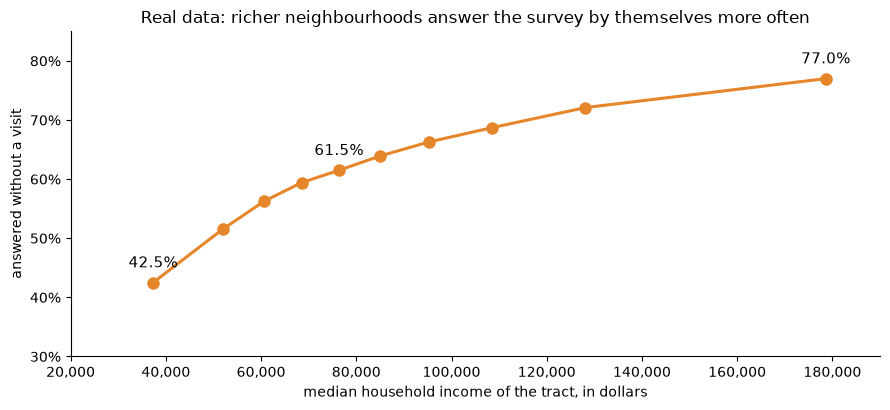

In [25]:
# American Community Survey, 2024 1-year, United States (tables B19013, B19025, B25003, B25119)
ACS_MEDIAN = 81_604
ACS_HOUSEHOLDS = 132_737_144
ACS_TOTAL_INCOME = 15_171_368_000_000
ACS_RENTER_HOUSEHOLDS = 46_101_640
ACS_RENTER_MEDIAN, ACS_OWNER_MEDIAN = 54_446, 100_721
TENURE_LEVEL, TENURE_SLOPE = 0.7288, 1.0568  # fitted so that the renter share and the renter median match

acs_mean = ACS_TOTAL_INCOME / ACS_HOUSEHOLDS
income = np.random.default_rng(SEED + 20).lognormal(np.log(ACS_MEDIAN), np.sqrt(2 * np.log(acs_mean / ACS_MEDIAN)), N_HOUSEHOLDS)
rank = income.argsort().argsort() / (N_HOUSEHOLDS - 1)
true_median, true_mean = np.median(income), income.mean()

def renter_probability(values):
    return 1 / (1 + np.exp(TENURE_LEVEL + TENURE_SLOPE * np.log(np.maximum(values, 1) / ACS_MEDIAN)))

renter_flag = np.random.default_rng(SEED + 21).random(N_HOUSEHOLDS) < renter_probability(income)
acs_fit = {
    "median of all households": (true_median, ACS_MEDIAN),
    "mean of all households": (true_mean, acs_mean),
    "renter share, %": (100 * renter_flag.mean(), 100 * ACS_RENTER_HOUSEHOLDS / ACS_HOUSEHOLDS),
    "renter median": (np.median(income[renter_flag]), ACS_RENTER_MEDIAN),
    "owner median (not fitted)": (np.median(income[~renter_flag]), ACS_OWNER_MEDIAN),
}
print(f"{'':<28}{'made-up country':>17}{'real, ACS 2024':>16}")
for name, (simulated, real) in acs_fit.items():
    print(f"{name:<28}{simulated:>17,.1f}{real:>16,.1f}")
print()

TRACT_FILE = "data/06-who-answers-the-income-survey/acs-self-response-by-tract-income.csv"
local = [path for path in (Path("..") / TRACT_FILE, Path(TRACT_FILE)) if path.exists()]
tract_table = pd.read_csv(local[0] if local else RAW + TRACT_FILE)
print(tract_table.to_string(index=False))

PRICED_OUT, SERVED, BY_ERROR, NOT_ADMITTED = "#c5cad3", "#2f6f4f", "#e6862a", "#ededed"
COUNTRY, SURVEY, INK = "#c9c9c9", "#e6862a", "#1f1f1f"
money = plt.FuncFormatter(lambda value, _: f"{value:,.0f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(tract_table.median_household_income, tract_table.self_response_rate, "o-", color=SURVEY, linewidth=2.2, markersize=8)
for position in (0, 4, 9):
    row = tract_table.iloc[position]
    ax.annotate(f"{row.self_response_rate:.1f}%", (row.median_household_income, row.self_response_rate), (0, 11),
                textcoords="offset points", ha="center", fontsize=10.5)
ax.set_ylim(30, 85)
ax.set_xlim(20_000, 190_000)
ax.xaxis.set_major_formatter(money)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))
ax.set_xlabel("median household income of the tract, in dollars")
ax.set_ylabel("answered without a visit")
ax.set_title("Real data: richer neighbourhoods answer the survey by themselves more often")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [26]:
VISIT_SHARE = 1 / 3   # share of silent addresses that get a visit (Census working paper, 2003)
VISIT_ANSWER = 0.67   # share of visits that get an answer (2021)
INCARCERATED = 1_967_297  # adult correctional facilities, 2020 Census
standard = 0.35

def self_response_probability(values):
    return np.interp(values, tract_table.median_household_income, tract_table.self_response_rate / 100)

def two_stage_survey(values, seed, visits=True, visit_answer=VISIT_ANSWER):
    draws = np.random.default_rng(seed)
    first = draws.random(len(values)) < self_response_probability(values)
    if not visits:
        return values[first], np.ones(first.sum())
    visited = ~first & (draws.random(len(values)) < VISIT_SHARE)
    second = visited & (draws.random(len(values)) < visit_answer)
    return (np.concatenate([values[first], values[second]]),
            np.concatenate([np.ones(first.sum()), np.full(second.sum(), 1 / VISIT_SHARE)]))

followup_results = {}
print(f"answers without a visit: {100 * self_response_probability(income).mean():.1f}% of households")
print(f"{'follow-up':<44}{'median error':>14}{'mean error':>12}")
for name, options in [
    ("no visits", dict(visits=False)),
    ("1 in 3 visited, 67% of visits answer", dict()),
    ("1 in 3 visited, 50% of visits answer", dict(visit_answer=0.50)),
]:
    values, weights = two_stage_survey(income, SEED + 8, **options)
    followup_results[name] = (pct_error(weighted_median(values, weights), true_median),
                              pct_error(np.average(values, weights=weights), true_mean))
    print(f"{name:<44}{followup_results[name][0]:>+13.1f}%{followup_results[name][1]:>+11.1f}%")

answers without a visit: 61.2% of households
follow-up                                     median error  mean error


no visits                                           +19.5%      +14.2%


1 in 3 visited, 67% of visits answer                 +4.3%       +3.2%


1 in 3 visited, 50% of visits answer                 +7.1%       +5.3%


### The first stage loses poorer households and the median moves

This picture shows the first stage only: the households that answer without a visit.

In [27]:
picture_sample, _ = two_stage_survey(income, SEED + 8, visits=False)
picture_median = np.median(picture_sample)
shift_label = f"{pct_error(picture_median, true_median):+.0f}%"

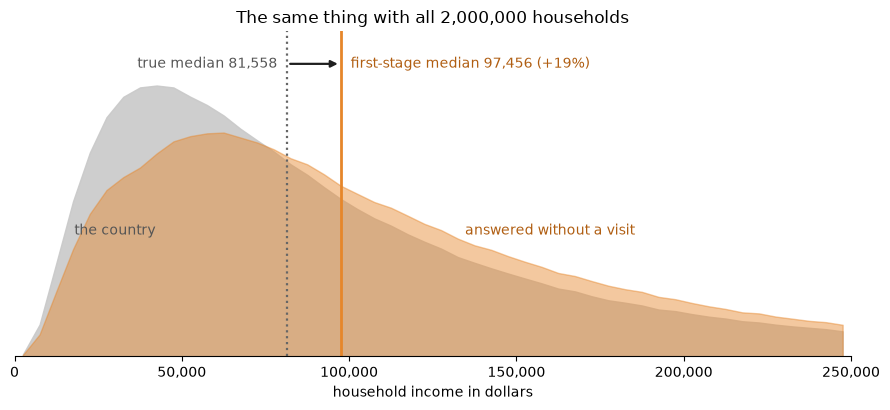

In [28]:
bins = np.arange(0, 251_000, 5_000)
centers = (bins[:-1] + bins[1:]) / 2
country_share = np.histogram(income, bins)[0] / len(income)
survey_share = np.histogram(picture_sample, bins)[0] / len(picture_sample)
top = max(country_share.max(), survey_share.max())

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(centers, country_share, color=COUNTRY, alpha=0.9)
ax.fill_between(centers, survey_share, color=SURVEY, alpha=0.45)
ax.axvline(true_median, color="#666666", linestyle=":", linewidth=1.6)
ax.axvline(picture_median, color=SURVEY, linewidth=2)
ax.annotate("", (picture_median, top * 1.08), (true_median, top * 1.08), arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.6))
ax.text(true_median - 3_000, top * 1.08, f"true median {true_median:,.0f}", ha="right", va="center", fontsize=10, color="#555555")
ax.text(picture_median + 3_000, top * 1.08, f"first-stage median {picture_median:,.0f} ({shift_label})", ha="left", va="center", fontsize=10, color="#b05e12")
ax.text(30_000, top * 0.45, "the country", ha="center", fontsize=10, color="#555555")
ax.text(160_000, top * 0.45, "answered without a visit", ha="center", fontsize=10, color="#b05e12")
ax.set_ylim(0, top * 1.2)
ax.set_xlim(0, 250_000)
ax.set_yticks([])
ax.xaxis.set_major_formatter(money)
ax.set_xlabel("household income in dollars")
ax.set_title("The same thing with all 2,000,000 households")
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
plt.show()

### The truth, with everybody in it

The truth for the housing rule is every household living separately, plus one zero-income unit for each homeless
person and each person in an adult correctional facility. The target group is every unit under 80% of the true median.

uncounted units: 40,877 = 2.00% of all units
true median 79,881; true limit 63,905; target group 39.5%
maximum rent 1,598 a month; income needed to pay it within 35%: 54,775


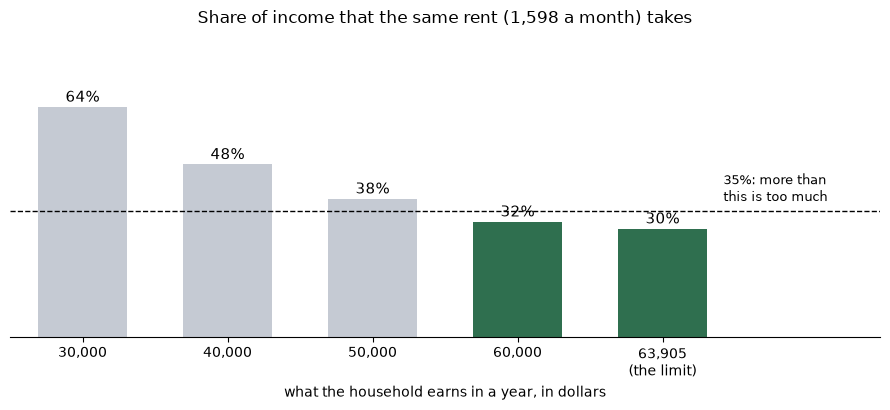

In [29]:
uncounted_people = HOMELESS_TOTAL + INCARCERATED
uncounted_units = round(N_HOUSEHOLDS * uncounted_people / ACS_HOUSEHOLDS)
full_truth = np.concatenate([income, np.zeros(uncounted_units)])
full_median = np.median(full_truth)
full_limit = LIMIT_SHARE * full_median
full_target = full_truth < full_limit
full_rent_year = RENT_SHARE * full_limit
print(f"uncounted units: {uncounted_units:,} = {100 * uncounted_units / len(full_truth):.2f}% of all units")
print(f"true median {full_median:,.0f}; true limit {full_limit:,.0f}; target group {100 * full_target.mean():.1f}%")
print(f"maximum rent {full_rent_year / 12:,.0f} a month; income needed to pay it within 35%: {full_rent_year / standard:,.0f}")

example_incomes = [30_000, 40_000, 50_000, 60_000, full_limit]
example_shares = [100 * full_rent_year / value for value in example_incomes]
labels = [f"{value:,.0f}" for value in example_incomes[:-1]] + [f"{full_limit:,.0f}\n(the limit)"]
colors = [SERVED if share <= 100 * standard else PRICED_OUT for share in example_shares]

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(labels, example_shares, color=colors, width=0.62)
for bar, share in zip(bars, example_shares):
    ax.text(bar.get_x() + bar.get_width() / 2, share + 1.5, f"{share:.0f}%", ha="center", fontsize=11)
ax.axhline(100 * standard, color="black", linestyle="--", linewidth=1)
ax.text(4.42, 100 * standard + 1.5, "35%: more than\nthis is too much", ha="left", va="bottom", fontsize=9.5)
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(0, 85)
ax.set_yticks([])
ax.set_xlabel("what the household earns in a year, in dollars")
ax.set_title(f"Share of income that the same rent ({full_rent_year / 12:,.0f} a month) takes")
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
plt.show()

### Every factor together

Each row adds one factor to the row above it. The survey is the two-stage survey from above.

everybody counted                            median  +0.0%   rent  1,598   target served  17.2 of 100   above the true limit   0% of served
homeless and prisoners left out              median  +2.1%   rent  1,631   target served  15.0 of 100   above the true limit  14% of served


and poorer households answer less            median  +6.5%   rent  1,701   target served  10.4 of 100   above the true limit  41% of served
and 1 in 50 households doubles up            median +10.2%   rent  1,760   target served   6.6 of 100   above the true limit  63% of served


and 1 in 20 households doubles up            median +15.5%   rent  1,845   target served   1.2 of 100   above the true limit  94% of served


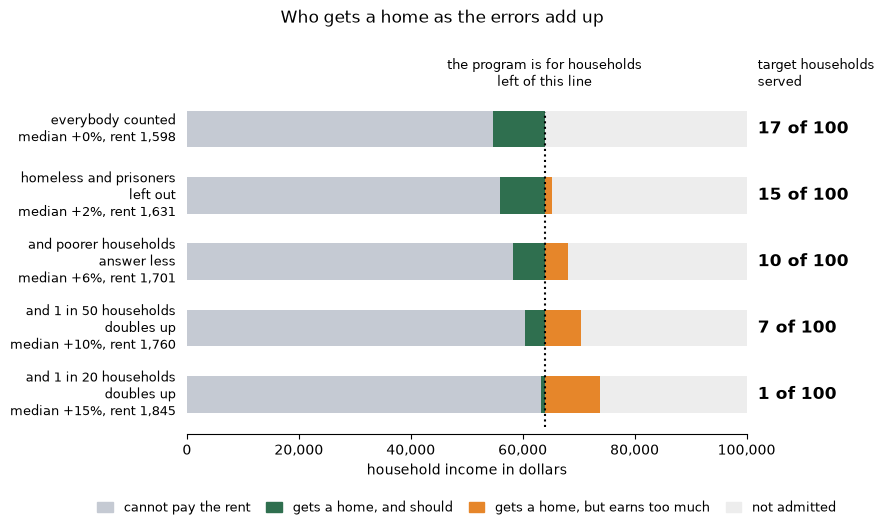

In [30]:
def merge_households(share):
    merge = np.random.default_rng(SEED + 3)
    leaving = merge.choice(np.flatnonzero(rank < 0.5), int(share * N_HOUSEHOLDS), replace=False)
    remaining = np.ones(N_HOUSEHOLDS, dtype=bool)
    remaining[leaving] = False
    receiving = merge.choice(np.flatnonzero(remaining), len(leaving), replace=False)
    combined = income.copy()
    combined[receiving] += income[leaving]
    return combined[remaining]

stack_rows = [
    ("everybody counted", (full_truth, np.ones(len(full_truth)))),
    ("homeless and prisoners\nleft out", (income, np.ones(len(income)))),
    ("and poorer households\nanswer less", two_stage_survey(income, SEED + 8)),
    ("and 1 in 50 households\ndoubles up", two_stage_survey(merge_households(0.02), SEED + 9)),
    ("and 1 in 20 households\ndoubles up", two_stage_survey(merge_households(0.05), SEED + 9)),
]
stack_results = []
right_edge = 100_000
fig, ax = plt.subplots(figsize=(9, 5.4))
for row, (name, (values, weights)) in enumerate(stack_rows):
    reported_median = weighted_median(values, weights)
    reported_limit = LIMIT_SHARE * reported_median
    floor = RENT_SHARE * reported_limit / standard
    can_pay = (full_truth >= floor) & (full_truth < reported_limit)
    served_target = can_pay & full_target
    served_by_error = can_pay & ~full_target
    result = (
        pct_error(reported_median, full_median),
        RENT_SHARE * reported_limit / 12,
        100 * served_target.sum() / full_target.sum(),
        100 * served_by_error.sum() / max(can_pay.sum(), 1),
    )
    stack_results.append(result)
    print(f"{name.replace(chr(10), ' '):<44} median {round(result[0], 1) + 0.0:+5.1f}%   rent {result[1]:>6,.0f}   target served {result[2]:5.1f} of 100   above the true limit {result[3]:3.0f}% of served")

    y = len(stack_rows) - 1 - row
    served_end = min(reported_limit, full_limit)
    ax.barh(y, floor, left=0, color=PRICED_OUT, height=0.55)
    ax.barh(y, max(served_end - floor, 0), left=floor, color=SERVED, height=0.55)
    ax.barh(y, max(reported_limit - max(served_end, floor), 0), left=max(served_end, floor), color=BY_ERROR, height=0.55)
    ax.barh(y, right_edge - reported_limit, left=reported_limit, color=NOT_ADMITTED, height=0.55)
    ax.text(-2_000, y, f"{name}\nmedian {round(result[0]) + 0:+d}%, rent {result[1]:,.0f}", ha="right", va="center", fontsize=9.5)
    served_label = "under 1 of 100" if 0 < result[2] < 1 else f"{round(result[2])} of 100"
    ax.text(right_edge + 2_000, y, served_label, ha="left", va="center", fontsize=12, fontweight="bold")
ax.axvline(full_limit, color="black", linestyle=":", linewidth=1.5, ymin=0.02, ymax=0.83)
ax.text(full_limit, len(stack_rows) - 0.42, "the program is for households\nleft of this line", ha="center", va="bottom", fontsize=9.5)
ax.text(right_edge + 2_000, len(stack_rows) - 0.42, "target households\nserved", ha="left", va="bottom", fontsize=9.5)
ax.set_xlim(0, right_edge)
ax.set_ylim(-0.6, len(stack_rows) + 0.25)
ax.set_yticks([])
ax.set_xticks([0, 20_000, 40_000, 60_000, 80_000, 100_000])
ax.xaxis.set_major_formatter(money)
ax.set_xlabel("household income in dollars")
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in (PRICED_OUT, SERVED, BY_ERROR, NOT_ADMITTED)]
ax.legend(handles, ["cannot pay the rent", "gets a home, and should", "gets a home, but earns too much", "not admitted"],
          loc="upper center", ncol=4, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, -0.14), handlelength=1.2, columnspacing=1.2)
ax.spines[["top", "right", "left"]].set_visible(False)
fig.suptitle("Who gets a home as the errors add up", fontsize=12)
fig.tight_layout()
plt.show()

The green piece is the group the program is for. It is gone once the reported median is about 17% too high, because
`0.35 / 0.30 = 1.167`: at that point the income needed to pay the maximum rent is above the true limit. The orange
piece replaces it, so the number of households served stays about the same.

### The same story as 100 dots

The country as 100 units: 98 households and 2 people with no household (homeless or in prison). A full-colour dot is seen by the median. A faded dot is not. Each picture applies one more effect. The solid
line is the median that the statistic reports at that step, taken from the full simulation above; the dotted line is
the true median with everybody counted.

The dots are an illustration with whole numbers of households, so the middle of the filled dots can sit one or two
dots away from the solid line.

98 households (34 renters) and 2 people with no household
silent after visits: 13; move in with another household: 5
reported medians: ['79,881', '81,558', '85,044', '87,997', '92,246'] ; first-stage median: 97,456
same rent, five households: ['64%', '48%', '38%', '32%', '30%']


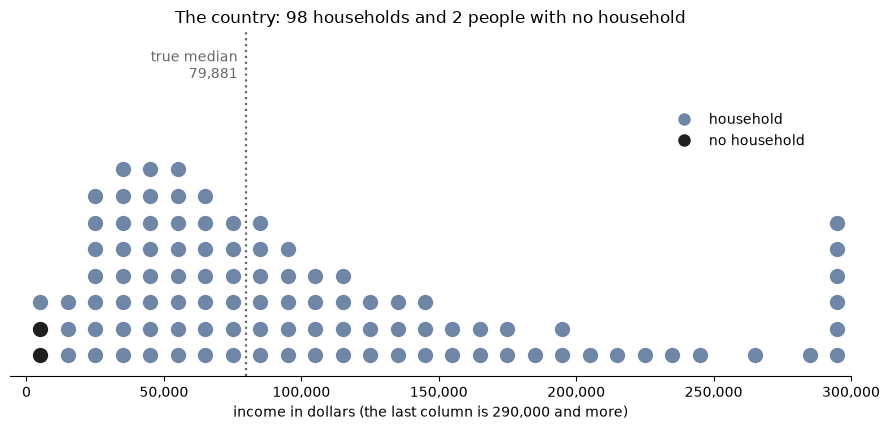

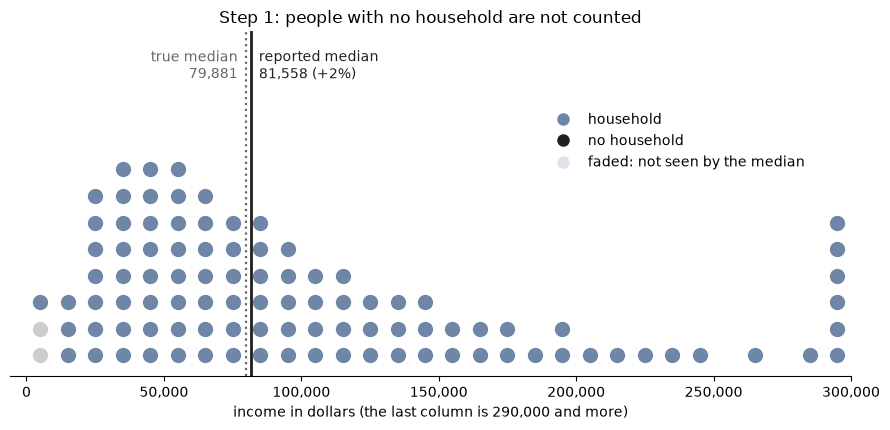

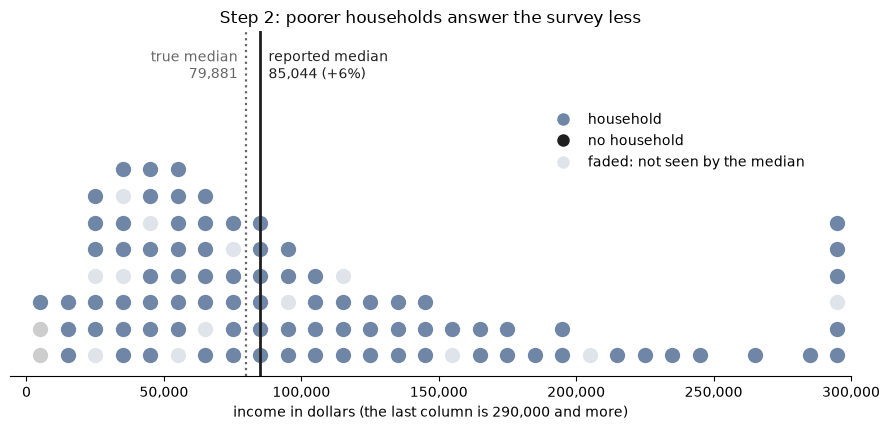

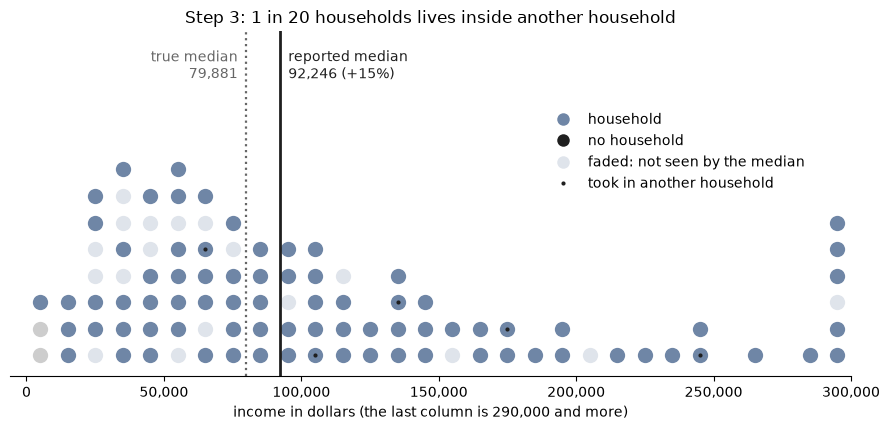

In [31]:
OWNER, RENTER, NO_HOUSEHOLD = "#8a94a6", "#e6862a", "#1f1f1f"
UNITS = 100
uncounted_dots = round(UNITS * uncounted_units / len(full_truth))
household_dots = UNITS - uncounted_dots
dot_income = np.quantile(income, (np.arange(household_dots) + 0.5) / household_dots)

def spread_over_tenths(expected_per_dot, offset):
    # turn expected values per dot into whole dots, tenth by tenth, picking evenly inside each tenth
    chosen = set()
    tenths = np.array_split(np.arange(len(expected_per_dot)), 10)
    expected = np.array([expected_per_dot[tenth].sum() for tenth in tenths])
    counts = np.floor(expected).astype(int)
    for tenth in np.argsort(-(expected - counts))[: int(round(expected.sum())) - counts.sum()]:
        counts[tenth] += 1
    for tenth, count in zip(tenths, counts):
        picks = (np.linspace(0, len(tenth) - 1, count + 2)[1:-1] + offset).round().astype(int) % len(tenth)
        chosen.update(int(tenth[pick]) for pick in picks)
    return chosen

renter_dots = spread_over_tenths(renter_probability(dot_income), 0)
missed_after_visits = (1 - self_response_probability(dot_income)) * (1 - VISIT_ANSWER)
silent_dots = spread_over_tenths(missed_after_visits, 1)
lower_half = [dot for dot in range(household_dots // 2) if dot not in silent_dots]
moving_dots = [lower_half[int(position)] for position in np.linspace(0, len(lower_half) - 1, 7)[1:-1]]
still_there = [dot for dot in range(household_dots) if dot not in silent_dots and dot not in moving_dots]
host_dots = [still_there[int(position)] for position in np.linspace(0, len(still_there) - 1, 7)[1:-1]]
print(f"{household_dots} households ({len(renter_dots)} renters) and {uncounted_dots} people with no household")
print(f"silent after visits: {len(silent_dots)}; move in with another household: {len(moving_dots)}")

HOUSEHOLD = "#6f86a6"

def draw_country(title, reported_median=None, hide_uncounted=False, hide_silent=False, doubled_up=False, tenure=False, lines=None):
    incomes = dot_income.copy()
    if doubled_up:
        for mover, host in zip(moving_dots, host_dots):
            incomes[host] += dot_income[mover]
    units = [(0.0, NO_HOUSEHOLD, not hide_uncounted, False)] * uncounted_dots
    for dot in range(household_dots):
        seen = not ((hide_silent and dot in silent_dots) or (doubled_up and dot in moving_dots))
        color = (RENTER if dot in renter_dots else OWNER) if tenure else HOUSEHOLD
        units.append((incomes[dot], color, seen, doubled_up and dot in host_dots))
    column_width, last_column = 10_000, 300_000
    stacking = {NO_HOUSEHOLD: 0, RENTER: 1, HOUSEHOLD: 1, OWNER: 2}  # renters at the bottom of each column, owners on top
    # a dot keeps its place in its column whether the median sees it or not
    units.sort(key=lambda unit: (int(min(unit[0], last_column - 1) // column_width), stacking[unit[1]], unit[0]))

    heights = {}
    fig, ax = plt.subplots(figsize=(9, 4.4))
    for value, color, seen, grew in units:
        column = int(min(value, last_column - 1) // column_width)
        level = heights.get(column, 0)
        heights[column] = level + 1
        x = column * column_width + column_width / 2
        ax.plot(x, level, "o", markersize=11, color=color, alpha=1.0 if seen else 0.22, markeredgewidth=0)
        if grew:
            ax.plot(x, level, "o", markersize=3, color=INK, markeredgewidth=0)
    top = 10
    if lines is None:
        lines = [(full_median, f"true median\n{full_median:,.0f}", ":", "#666666", "right")]
        if reported_median is not None and abs(reported_median - full_median) > 1:
            lines.append((reported_median, f"reported median\n{reported_median:,.0f} ({pct_error(reported_median, full_median):+.0f}%)", "-", INK, "left"))
    for value, label, style, color, side in lines:
        ax.axvline(value, color=color, linestyle=style, linewidth=1.6 if style == ":" else 2)
        ax.text(value + (3_000 if side == "left" else -3_000), top + 0.9, label, ha=side, va="center", fontsize=10, color=color)

    dot = lambda color, label, **kwargs: plt.Line2D([], [], marker="o", linestyle="", markersize=9, markeredgewidth=0, color=color, label=label, **kwargs)
    if tenure:
        handles = [dot(OWNER, "owner"), dot(RENTER, "renter"), dot(NO_HOUSEHOLD, "no household")]
    else:
        handles = [dot(HOUSEHOLD, "household"), dot(NO_HOUSEHOLD, "no household")]
        if hide_uncounted:
            handles.append(dot(HOUSEHOLD, "faded: not seen by the median", alpha=0.22))
        if doubled_up:
            handles.append(plt.Line2D([], [], marker="o", linestyle="", markersize=3, markeredgewidth=0, color=INK, label="took in another household"))
    ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=10, bbox_to_anchor=(0.96, 0.8))
    ax.set_ylim(-0.8, top + 2.2)
    ax.set_xlim(-6_000, last_column)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(money)
    ax.set_xlabel("income in dollars (the last column is 290,000 and more)")
    ax.set_title(title)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout()
    plt.show()

reported = [full_median * (1 + result[0] / 100) for result in stack_results]
print("reported medians:", [f"{value:,.0f}" for value in reported], "; first-stage median:", f"{picture_median:,.0f}")
print("same rent, five households:", [f"{share:.0f}%" for share in example_shares])
draw_country("The country: 98 households and 2 people with no household")
draw_country("Step 1: people with no household are not counted", reported[1], hide_uncounted=True)
draw_country("Step 2: poorer households answer the survey less", reported[2], hide_uncounted=True, hide_silent=True)
draw_country("Step 3: 1 in 20 households lives inside another household", reported[4], hide_uncounted=True, hide_silent=True, doubled_up=True)

### A second, separate problem: the ruler is taken from everybody, and the program is for renters

This part has nothing to do with missing people. The picture shows the country with everybody counted, and only
colours the households by owner or renter.

A rental program is for renters. Renters and owners are assigned as described at the top of this section, so the
renter share and the renter median are the real 2024 figures. The true renter median counts every renter household living separately, plus
the people with no household. The reported renter median is what the same two-stage survey reports for renter
households after the same three effects.

true renter median, with people with no household: 51,491
                                        renter median    error   all households, error
everybody counted                              51,491    +0.0%                   +0.0%
people with no household left out              54,446    +5.7%                   +2.1%
and poorer households answer less              56,630   +10.0%                   +6.5%
and 1 in 20 households doubles up              61,248   +18.9%                  +15.5%
the ruler (reported median of all households) is +79% above the true renter median
true 80% limit 63,905; median renter household 54,446; renter households under the limit: 58.3%; maximum rent takes 35.2% of the median renter's income


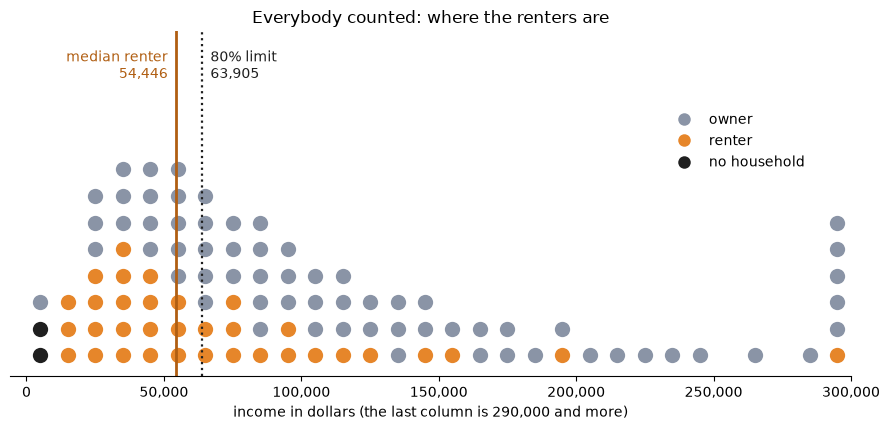

In [32]:
def merged_renters(share):
    merge = np.random.default_rng(SEED + 3)
    leaving = merge.choice(np.flatnonzero(rank < 0.5), int(share * N_HOUSEHOLDS), replace=False)
    remaining = np.ones(N_HOUSEHOLDS, dtype=bool)
    remaining[leaving] = False
    receiving = merge.choice(np.flatnonzero(remaining), len(leaving), replace=False)
    combined = income.copy()
    combined[receiving] += income[leaving]
    return combined[remaining & renter_flag]

renter_truth = np.concatenate([income[renter_flag], np.zeros(uncounted_units)])
renter_true_median = np.median(renter_truth)
renter_rows = [
    ("everybody counted", (renter_truth, np.ones(len(renter_truth)))),
    ("people with no household left out", (income[renter_flag], np.ones(renter_flag.sum()))),
    ("and poorer households answer less", two_stage_survey(income[renter_flag], SEED + 11)),
    ("and 1 in 20 households doubles up", two_stage_survey(merged_renters(0.05), SEED + 11)),
]
renter_results = []
all_errors = [stack_results[0][0], stack_results[1][0], stack_results[2][0], stack_results[4][0]]
print(f"true renter median, with people with no household: {renter_true_median:,.0f}")
print(f"{'':<38}{'renter median':>15}{'error':>9}{'all households, error':>24}")
for (name, (values, weights)), all_error in zip(renter_rows, all_errors):
    median = weighted_median(values, weights)
    renter_results.append((median, pct_error(median, renter_true_median)))
    print(f"{name:<38}{median:>15,.0f}{round(renter_results[-1][1], 1) + 0.0:>+8.1f}%{round(all_error, 1) + 0.0:>+23.1f}%")
print(f"the ruler (reported median of all households) is {pct_error(reported[4], renter_true_median):+.0f}% above the true renter median")

renter_household_median = np.median(income[renter_flag])
print(f"true 80% limit {full_limit:,.0f}; median renter household {renter_household_median:,.0f}; "
      f"renter households under the limit: {100 * (income[renter_flag] < full_limit).mean():.1f}%; "
      f"maximum rent takes {100 * RENT_SHARE * full_limit / renter_household_median:.1f}% of the median renter's income")
draw_country("Everybody counted: where the renters are", tenure=True, lines=[
    (renter_household_median, f"median renter\n{renter_household_median:,.0f}", "-", "#b05e12", "right"),
    (full_limit, f"80% limit\n{full_limit:,.0f}", ":", INK, "left"),
])

## Checks

These assertions pin the numbers quoted in the article. If one fails, the article and the notebook disagree.

In [33]:
EXPECT_BELOW_MEAN = 66.6
EXPECT_SCENARIOS = {  # (mean error %, median error %)
    "Fair": (0.0, 0.0),
    "Poor answer less": (6.6, 8.0),
    "Rich answer less": (-6.5, -7.3),
    "Both tails answer less": (-3.0, 0.0),
}
EXPECT_GAP5 = (1.7, 2.0)
EXPECT_WEIGHTED = (3.5, 4.5)
EXPECT_HOMELESS_MEDIAN = 0.59
EXPECT_SWING = {"sheltered": (9.4, 15.3), "unsheltered": (21.0, 42.6)}  # (typical change %, share over 25%)
EXPECT_COUNT_ERROR = {"sheltered": 8, "unsheltered": 14}
EXPECT_BEST_GAP = {"sheltered": 9.6, "unsheltered": 16.1}
EXPECT_MERGED = (11.1, 18.5)
EXPECT_WITH_HOMELESS = {  # (mean error %, median error %) against a truth that includes homeless households
    "Fair": (0.5, 0.6),
    "Poor answer less": (7.2, 8.7),
    "Rich answer less": (-6.0, -6.8),
    "Both tails answer less": (-2.5, 0.6),
}
EXPECT_LIMIT = {  # (limit error %, % under limit, % eligible only by error)
    "homeless not counted": (0.6, 40.1, 0.3),
    "+ one in ten doubled up": (19.2, 47.8, 8.0),
    "+ poor answer less (5-point gap)": (21.2, 48.6, 8.8),
    "+ poor answer less (20-point gap)": (27.7, 51.0, 11.2),
}
EXPECT_BURDEN = {"true": (100.0, 50.1, 50), "reported": (100.0, 66.9, 61)}  # (% over 30, % over 50, typical %)
EXPECT_HONOLULU_80 = (92_400, 83, 44.42)  # income needed, % of one minimum-wage job, hourly wage needed
EXPECT_SERVED = {  # (% of target served, % of all households, admitted and served % of all)
    ("true", 0.30): (0.0, 0.0, 0.0), ("true", 0.35): (16.6, 6.6, 6.6),
    ("true", 0.40): (30.1, 12.0, 12.0), ("true", 0.50): (49.9, 19.9, 19.9),
    ("reported", 0.30): (0.0, 0.0, 0.0), ("reported", 0.35): (0.0, 0.0, 7.0),
    ("reported", 0.40): (10.4, 4.1, 12.9), ("reported", 0.50): (33.1, 13.2, 21.9),
}
EXPECT_EXTRA_RENT = (8_363, 4_431, 3_708)  # dollars a year per unit: rule itself, wrong median, Honolulu adjustment
EXPECT_BIAS_35 = {  # gap: (% of target served, target % of all, only by error % of all, wrong % of served)
    0: (16.8, 6.7, 0.0, 0), 5: (14.8, 5.9, 0.9, 13), 20: (8.6, 3.4, 3.5, 51), 40: (0.3, 0.1, 6.9, 98),
}
EXPECT_STACK = [(0.0, 17.2, 0), (2.1, 15.0, 14), (6.5, 10.4, 41), (10.2, 6.6, 63), (15.5, 1.2, 94)]
EXPECT_FOLLOWUP = {"no visits": (19.5, 14.2), "1 in 3 visited, 67% of visits answer": (4.3, 3.2), "1 in 3 visited, 50% of visits answer": (7.1, 5.3)}  # (median %, mean %)  # (median %, target served of 100, % of served above the true limit)
EXPECT_RENTER_ERRORS = [0.0, 5.7, 10.0, 18.9]  # renter median error % after each step

def close(value, expected, tolerance=0.15):
    return abs(value - expected) <= tolerance

assert close(100 * below_mean, EXPECT_BELOW_MEAN)
for name, (mean_error, median_error) in EXPECT_SCENARIOS.items():
    assert close(results[name][1], mean_error), (name, results[name])
    assert close(results[name][2], median_error), (name, results[name])
assert close(mean_errors[1], EXPECT_GAP5[0]) and close(median_errors[1], EXPECT_GAP5[1])
assert close(weighted_mean_error, EXPECT_WEIGHTED[0]) and close(weighted_median_error, EXPECT_WEIGHTED[1])
assert close(homeless_results["all homeless"][2], EXPECT_HOMELESS_MEDIAN, 0.03)
for kind in EXPECT_SWING:
    assert close(swing[kind][0], EXPECT_SWING[kind][0]) and close(swing[kind][1], EXPECT_SWING[kind][1])
    assert round(count_error[kind]) == EXPECT_COUNT_ERROR[kind]
    assert close(best_gap[kind], EXPECT_BEST_GAP[kind])
for name, (mean_error, median_error) in EXPECT_WITH_HOMELESS.items():
    assert close(with_homeless[name][0], mean_error) and close(with_homeless[name][1], median_error), name
assert close(merged_mean_error, EXPECT_MERGED[0]) and close(merged_median_error, EXPECT_MERGED[1])
for name, expected in EXPECT_LIMIT.items():
    assert all(close(value, target) for value, target in zip(limit_results[name][1:4], expected)), (name, limit_results[name])
for name, expected in EXPECT_BURDEN.items():
    assert all(close(value, target, 0.6) for value, target in zip(burden_results[name], expected)), (name, burden_results[name])
assert all(close(value, target, 0.6) for value, target in zip(honolulu[80], EXPECT_HONOLULU_80)), honolulu[80]
for key, expected in EXPECT_SERVED.items():
    assert all(close(value, target_value) for value, target_value in zip(served_results[key], expected)), (key, served_results[key])
assert all(close(value, expected, 1.0) for value, expected in zip((design_per_unit, mirage_per_unit, honolulu_extra), EXPECT_EXTRA_RENT))
for gap, expected in EXPECT_BIAS_35.items():
    row = bias_results[0.35][list(gaps).index(gap)]
    assert all(close(value, target_value, 0.6) for value, target_value in zip(row, expected)), (gap, row)
for result, (median_error, served, wrong) in zip(stack_results, EXPECT_STACK):
    assert close(result[0], median_error) and close(result[2], served) and close(result[3], wrong, 0.6), result
for name, expected in EXPECT_FOLLOWUP.items():
    assert close(followup_results[name][0], expected[0]) and close(followup_results[name][1], expected[1]), (name, followup_results[name])
assert all(close(result[1], expected) for result, expected in zip(renter_results, EXPECT_RENTER_ERRORS)), renter_results
for name, (simulated, real) in acs_fit.items():
    assert abs(simulated / real - 1) < 0.005, (name, simulated, real)
print("all article numbers reproduced")

all article numbers reproduced
